# Housing Activity Sales in Collin County (Texas)
This analysis explores the Housing Activity dataset from the Texas A&M University: Texas Real Estate Research Center.

# Research Question
How healthy is the Collin County housing market from 2020 - 2025, and do current trends indicate that it will continue to improve over the next few years?

-----------------



# Datasets
1. Housing Activity in Collin County from 2020 - 2025:
https://trerc.tamu.edu/data/housing-activity/?data-County=Collin+County.
This dataset explores the monthly sales, average/median prices, end of month listings, months inventory, and the sales and growth YoY% percentage of Collin County housing activity.

# Model Summary
## Model 1:
- Type: Spread and Variation of Key Numeric Features Box Plot
- Dataset: Housing Activity in Collin County from 2020 - 2025
- Metric(s) used: Mean, Median, Mode, Min, Max, Range, IQR, Standard Deviation values
- Key insight(s): The market is active but unstable, demand-driven but fluctuating, and impacted by supply contraints. We see this, for example, in the Sales YoY% changes but also in the other variables, which do not show stability as some months surge while others sharply decline. There are wide ranges and some tight spreads in others. The results show that even with the fluctuations, Collin County remained a low-inventory but competitive market during 2020 - 2025.

## Model 2:
- Type: Correlation
- Dataset: Housing Activity in Collin County from 2020 - 2025
- Metric(s) used: Correlation values
- Key insight(s): The Dollar Volume is driven primarily by the Average and Median home prices and secondarily by Sales, while Months Inventory levels and YoY percentages have a relatively week relationship. Sales and Dollar Volume YoY percentages have a lower correlation because these percentages tend to jump or drop as sales may rise or slow down in the next months. The YoY percentages are changing variables that are not fully captured by the correlation values.

## Model 3:
- Type: Linear Regression
- Dataset: Housing Activity in Collin County from 2020 - 2025
- Metric(s) used: Coefficients, R-squared
- Key insight(s): A 1% increase in Sales raises predicted sales increase by 4.88 homes, and a full 100% increase increases predicted sales by 487.62 homes. The coefficient for Dollar Volume is 0, meaning the changes in total revenue do not predict changes in the number of homes sold. The scale of Dollar Volume (millions) also causes the coefficient to be 0. The R^2 value shows that 80% of the variation in sales is explained by both variables, but essentially, all prediction ability comes from the Sales YoY%. To predict how many homes will be sold, Sales YoY% is the only meaningful predictor. Dollar Volume does not predict sales. This indicates that demand trends, not total market revenue, determine the number of homes sold in a given month.

## Model 4:
- Type: Logistic Regression
- Dataset: Housing Activity in Collin County from 2020 - 2025
- Metric(s) used: Accuracy, Precision, Recall, F1 Score, Feature Importance (Coefficients, Odds Ratio)
- Key insight(s): The factors that increase the odds that a month is a high sales month are Dollar Volume, with the strongest odds ratio of 7.13, and Sales YoY% with 2.73. This means that months with a higher Dollar Volume are very likely to be high sales months. High sales months generate high total revenue. The model accurately predicts high sales months as it has captured this pattern throughout the accuracy, precision, recall, and F1 score percentages at 85.7%. As discussed in the linear regression model, this does not mean Dollar Volume can meaningfully predict the number of homes sold (sales). This indicates that the total market revenue and demand growth drive those high selling months.
-----------------


## Results
The results of the analysis show that the Collin County housing market experienced substantial unpredictability followed by a clear stabilization, and it is likely that the unpredictability is during the 2020 - 2021 due to COVID-19 and stabilization from 2022 - 2025. The statistics reveal wide fluctuations in those early years, particularly in Sales YoY%, Dollar Volume, and Active Listings. These values tightened over time, indicating a return to a more predictable market behavior. Prices remained relatively stable throughout the period, with Average and Median Price showing moderate spreads and limited impact from outliers. The correlation analysus indicates that Dollar Volume is strongly associated with both prices and total sales, confirming that higher price levels and increased transaction activity of sales contribute directly to the overall markey revenue. The Linear Regression results show that Sales YoY% is a significant predictor of the number of homes sold, suggesting that demand changes influence market activity more than total revenue does. Logistic regression further reveals that high sales months have high Dollar Volume and positive Sales YoY%, with the model accurately classifying these months 85.7% of the time. Together, these results potray a market that has moved from instability to consistent, healthy behavior.

## Conclusion and Recommendations
Overall, the data indicates that the Collin County housing market has remained healthy and resilient throughout the observed period of 2020 to 2025. Prices increased steadily over time, and the model's behavior in linear regression shows that the market transitioned from rapid growth to a more stable and predictable pattern. Even in the spread and variance model, the slight negative deviations were small and did not signal a reversal of the long-term upward trend. Based on this modeling, current conditions suggest that the market is likely to continue improving, but at a gradual and steady pace. To support this long-term health, Collin County policymakers can track the monthly inventory levels and ensure new housing development keeps pace with the demand-driven market. Buyegrs should remain aware that although price growth has slowed slightly, it still trends upward, meaning early purchasing may be financially beneficial. For analysts and local agenicies, continuing to track the patterns and updating regression models with current data would help detect any new signs. Overall, the data supports the optimistic outlook for Collin County's housing market.

In [ ]:
# Mount at Google Drive location
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Basic import statements
import pandas as pd
from scipy import stats

In [ ]:
# Path to the file on Google Drive
df = pd.read_csv("/content/drive/MyDrive/Data/Housing_Activity.csv")
df.head()

,Market Name,Date,Sales,Sales YoY%,Dollar Volume,Dollar Volume YoY%,Average Price,Median Price,Active Listings EOM,Months Inventory
0,Collin County,2025-10-01,1443,0.0833,752276068,0.0086,521327,445000,6442,4.50
1,Collin County,2025-09-01,1480,0.1229,771636056,0.0643,521375,448250,6506,4.57
2,Collin County,2025-08-01,1545,0.0663,832715011,-0.0095,538974,465000,6781,4.81
3,Collin County,2025-07-01,1630,0.1051,903402200,0.0567,554234,485000,6999,5.00
4,Collin County,2025-06-01,1672,0.1343,979997691,0.1178,586123,482000,6805,4.90


In [ ]:
# Check if dataframe was loaded correctly
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Market Name          178 non-null    object 
 1   Date                 178 non-null    object 
 2   Sales                178 non-null    int64  
 3   Sales YoY%           178 non-null    float64
 4   Dollar Volume        178 non-null    int64  
 5   Dollar Volume YoY%   178 non-null    float64
 6   Average Price        178 non-null    int64  
 7   Median Price         178 non-null    int64  
 8   Active Listings EOM  178 non-null    int64  
 9   Months Inventory     178 non-null    float64
dtypes: float64(3), int64(5), object(2)
memory usage: 14.0+ KB


# Data Types

*   Market Name: Area of market (in this case, it is all Collin County)
*   Date: Date of sales each month
*   Sales: Count of sales each month
*   Sales YoY%: Comparison of sales from specific period to same period in previous year
*   Dollar Volume: Summing final price of sales (tells us overall flow of money or general health of real estate market)
*   Dollar Volume YoY%: Comparison of dollar volume from specific period to same period in previous year
*   Average Price: Calculated average price
*   Median Price: Calculated median price
*   Active Listings EOM: Count of physical properties at the EOM
*   Months Inventory: Calculated ratio of active listings divided by average monthly sales


| Column Name   | Description                          | Data Type                      | Explanation                                                                          |
| ------------- | ------------------------------------ | ------------------------------ | ------------------------------------------------------------------------------------ |
| `Market Name` | Name of county | **String/Text** | County's name |
| `Date`    | Date of sales (each month) | **Ordinal (Qualitative)** | No difference in order |
| `Sales` | Number of sales | **Discrete (Quantitative)** | Can be counted |
| `Sales YoY%` | Comparison of sales from specific period to same period in previous year |  **Continuous (Quantitative)** | A range of numbers, includes percentages |
| `Dollar Volume` | Final sale prices of all properties sold | **Continuous (Quantitative)** | A range of numbers, can have fractional values |
| `Dollar Volume YoY%` | Comparison of dollar volume from specific period to same period in previous year | **Continuous (Quantitative)** | A range of numbers, includes percentages |
| `Average Price` | Calculated average price | **Continuous (Quantitative)** | A range of numbers, can have fractional values |
| `Median Price` | Calculated median price | **Continuous (Quantitative)** | A range of numbers, can have fractional values |
| `Active Listings EOM` | Count of physical properties at the EOM |  **Discrete (Quantitative)** | Can be counted |  
| `Months Inventory` | Active listings divided by monthly sales |  **Continuous (Quantitative)** | A range of numbers, can have fractional values |

# Calculate the mean, median, and mode (measures of central tendency)
For `Sales`, `Sales YoY%`, `Dollar Volume`, `Dollar Volume YoY%`, `Average Price`, `Median Price`, `Active Listing EOM`, and `Months Inventory`

In [ ]:
# Make sure Date is datetime
df['Date'] = pd.to_datetime(df['Date'])

# Filter to 2020–2025
df_filtered = df[(df['Date'].dt.year >= 2020) & (df['Date'].dt.year <= 2025)]

# Select numeric columns to analyze (continuous or discrete quantitative variables)
cols = ["Sales", "Sales YoY%", "Dollar Volume", "Dollar Volume YoY%", "Average Price", "Median Price", "Active Listings EOM", "Months Inventory"]

# Loop through each column and compute measures of spread
for col in cols:
    print(f"\n--- {col.upper()} ---")

    # Calculate Mean
    mean_age = df_filtered[col].mean()
    print(f"Mean: {mean_age}")

    # Calculate Median
    median_age = df_filtered[col].median()
    print(f"Median: {median_age}")

    # Calculate Mode
    mode_result = stats.mode(df[col], keepdims=True)
    mode_age = mode_result.mode[0]
    count_mode = mode_result.count[0]
    print(f"Mode: {mode_age} (appears {count_mode} times)")


--- SALES ---
Mean: 1391.3714285714286
Median: 1410.5
Mode: 743 (appears 2 times)

--- SALES YOY% ---
Mean: 0.017821428571428575
Median: 0.03635
Mode: 1.0 (appears 12 times)

--- DOLLAR VOLUME ---
Mean: 732083906.0142857
Median: 752076217.0
Mode: 124718596 (appears 1 times)

--- DOLLAR VOLUME YOY% ---
Mean: 0.08853857142857142
Median: 0.07235
Mode: 1.0 (appears 12 times)

--- AVERAGE PRICE ---
Mean: 528460.9
Median: 551898.0
Mode: 227177 (appears 1 times)

--- MEDIAN PRICE ---
Mean: 461276.0857142857
Median: 479995.0
Mode: 335000 (appears 4 times)

--- ACTIVE LISTINGS EOM ---
Mean: 3103.785714285714
Median: 3009.0
Mode: 2470 (appears 2 times)

--- MONTHS INVENTORY ---
Mean: 2.283285714285714
Median: 2.3049999999999997
Mode: 2.39 (appears 3 times)


# Spread and Variation for each key numeric feature

## Calculate Range, Interquartile Range, and Standard Deviation

For `Sales`, `Sales YoY%`, `Dollar Volume`, `Dollar Volume YoY%`, `Average Price`, `Median Price`, `Active Listing EOM`, and `Months Inventory`

In [ ]:
# Make sure Date is datetime
df['Date'] = pd.to_datetime(df['Date'])

# Filter to 2020–2025
df_filtered = df[(df['Date'].dt.year >= 2020) & (df['Date'].dt.year <= 2025)]

# Select numeric columns to analyze (continuous or discrete quantitative variables)
cols = ["Sales", "Sales YoY%", "Dollar Volume", "Dollar Volume YoY%", "Average Price", "Median Price", "Active Listings EOM", "Months Inventory"]

# Loop through each column and compute measures of spread
for col in cols:
    # Calculate and print min, max, range, IQR, and standard deviation for each column
    # Range
    min_value = df_filtered[col].min()
    max_value = df_filtered[col].max()
    data_range = max_value - min_value

    # IQR
    qtr1_value = df_filtered[col].quantile(0.25)
    qtr3_value = df_filtered[col].quantile(0.75)
    iqr_value = qtr3_value - qtr1_value

    # Standard Deviation
    std_value = df_filtered[col].std()

    print(f"\n--- {col.upper()} ---")
    if "YoY" in col:
    # Print Results
      # For the smaller numbers
      print(f"Min: {min_value:.4f} | Max: {max_value:.4f}")
      print(f"Range: {data_range:,.4f}")
      print(f"IQR: {iqr_value:,.4f}")
      print(f"Standard Deviation: {st`d_value:,.4f}")
    else: # For the large numbers
      print(f"Min: {min_value:.0f} | Max: {max_value:.0f}")
      print(f"Range: {data_range:,.0f}")
      print(f"IQR: {iqr_value:,.0f}")
      print(f"Standard Deviation: {std_value:,.0f}")




--- SALES ---
Min: 780 | Max: 2210
Range: 1,430
IQR: 382
Standard Deviation: 283

--- SALES YOY% ---
Min: -0.3266 | Max: 0.3458
Range: 0.6724
IQR: 0.2108
Standard Deviation: 0.1586

--- DOLLAR VOLUME ---
Min: 357676870 | Max: 1000650744
Range: 642,973,874
IQR: 211,843,918
Standard Deviation: 160,526,272

--- DOLLAR VOLUME YOY% ---
Min: -0.2934 | Max: 0.6934
Range: 0.9868
IQR: 0.1390
Standard Deviation: 0.1820

--- AVERAGE PRICE ---
Min: 371632 | Max: 645192
Range: 273,560
IQR: 76,647
Standard Deviation: 71,547

--- MEDIAN PRICE ---
Min: 335000 | Max: 579250
Range: 244,250
IQR: 62,325
Standard Deviation: 61,183

--- ACTIVE LISTINGS EOM ---
Min: 685 | Max: 6999
Range: 6,314
IQR: 2,000
Standard Deviation: 1,605

--- MONTHS INVENTORY ---
Min: 0 | Max: 5
Range: 5
IQR: 2
Standard Deviation: 1


# Box Plot

For `Sales`, `Sales YoY%`, `Dollar Volume`, `Dollar Volume YoY%`, `Average Price`, `Median Price`, `Active Listing EOM`, and `Months Inventory`

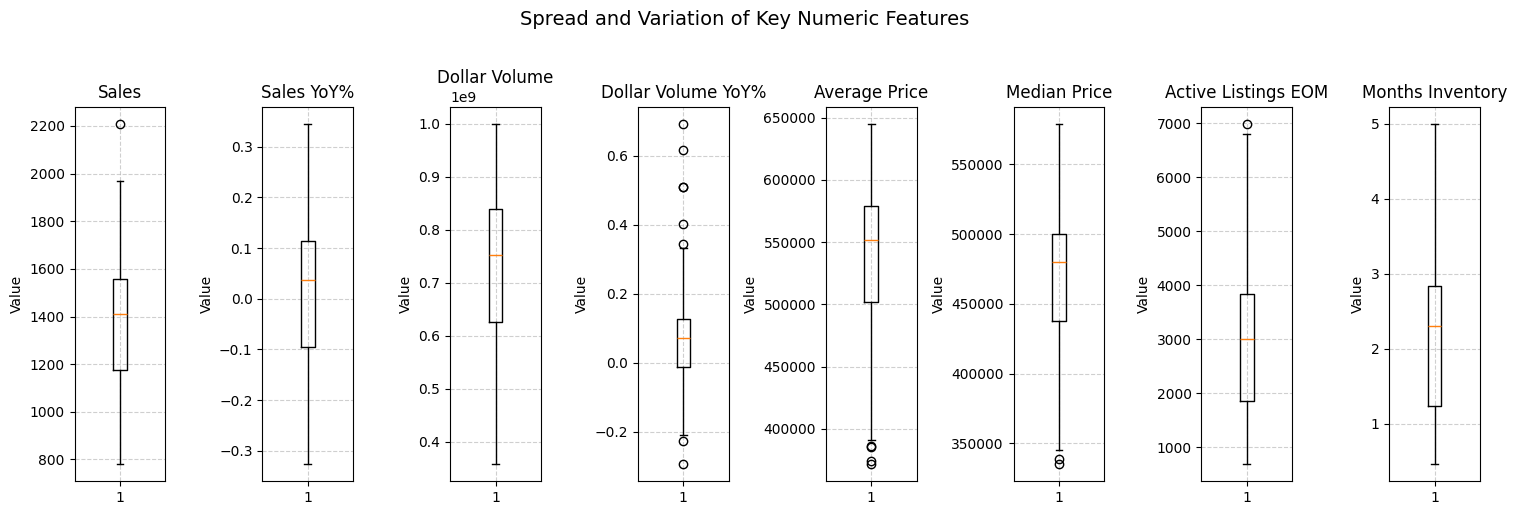

In [ ]:
import matplotlib.pyplot as plt

# Make sure Date is datetime
df['Date'] = pd.to_datetime(df['Date'])

# Filter to 2020–2025
df_filtered = df[(df['Date'].dt.year >= 2020) & (df['Date'].dt.year <= 2025)]

# Define numeric columns to visualize
cols = ["Sales", "Sales YoY%", "Dollar Volume", "Dollar Volume YoY%", "Average Price", "Median Price", "Active Listings EOM", "Months Inventory"]

# Create a row of 5 subplots (one for each variable), figure size 15x5 inches
fig, axes = plt.subplots(nrows=1, ncols=len(cols), figsize=(15, 5))

# Loop over each column and its corresponding subplot axis
for i, col in enumerate(cols):
  # Create a box plot for this column (drop missing values first)'
  axes[i].boxplot(df_filtered[col].dropna(), vert=True)
  # Set the title of this subplot to the column name
  axes[i].set_title(col)
  # Label the y-axis
  axes[i].set_ylabel("Value")
  # Add a light dashed grid for readibility
  axes[i].grid(True, linestyle="--", alpha=0.6)

# Add a main title across all subplots
plt.suptitle("Spread and Variation of Key Numeric Features", fontsize=14, y=1.02)
# Adjust layout so titles and labels dont overlap
plt.tight_layout()
# Display the figure
plt.show()

* The reason Sales YoY% has a negative value for min is because a negative Sales YoY% indicates an actual drop in sales for a period (in this case, 2020 - 2025). The min value is negative, which signifies the largest decrease in some months during that time period was by 32.66%. On the other hand, others had a 34.6% increase compared to the same month last year. The IQR shows that YoY changes are within 21%. The typical month by month change is 16%. So, months vary but with some big increases or decreases. The same logic of Sales YoY% applies to Dollar Volume YoY%.

* There is a very large spread for Dollar Volume, which means some months brought much more revenue. The Standard Deviation indicates the Dollar Volume fluctuates a lot by month. High priced properties skew the totals upward.

* As for Average Price, montly averages seem to flactuate but are generally concentrated because the IQR (77K) and STD (72K) show the typical amount (which are close in value).

* As for Median Price, it seems to be less affected by outliers (extreme sales) compared to Average Price. The spread is tighter. IQR (62K)
STD (61K)

* As for Active Listings, some months had few while others had almost 7,000. The Active Listings seem to fluctuate a lot, which can affect prices and sales activity.

* Month Inventory shows a typically low supply, but some supply each month has a moderate value of almost 3 (based on box plot).

* The lowest number of Sales in this period was 780, while the highest was 2210. The IQR shows a typical variation and the monthly sales deviate about 283 units from the mean. Sales vary moderately month by month with some fomths being higher or lower than the typical.

# Correlation
For `Sales`, `Sales YoY%`, `Dollar Volume`, `Dollar Volume YoY%`, `Average Price`, `Median Price`, `Active Listing EOM`, and `Months Inventory`

In [ ]:
# Make sure Date is datetime
df['Date'] = pd.to_datetime(df['Date'])

# Filter to 2020–2025
df_filtered = df[(df['Date'].dt.year >= 2020) & (df['Date'].dt.year <= 2025)]

# Select numeric columns to explore
cols = ["Sales", "Sales YoY%", "Dollar Volume", "Dollar Volume YoY%", "Average Price", "Median Price", "Active Listings EOM", "Months Inventory"]

# Display the correlation matrix
df[cols].corr()

,Sales,Sales YoY%,Dollar Volume,Dollar Volume YoY%,Average Price,Median Price,Active Listings EOM,Months Inventory
Sales,1.000000,-0.299185,0.734405,-0.255678,0.310262,0.324394,0.111203,-0.149282
Sales YoY%,-0.299185,1.000000,-0.432074,0.953903,-0.469609,-0.493401,0.279039,0.611997
Dollar Volume,0.734405,-0.432074,1.000000,-0.410659,0.857528,0.859124,0.063290,-0.220467
Dollar Volume YoY%,-0.255678,0.953903,-0.410659,1.000000,-0.468481,-0.493036,0.081200,0.429847
Average Price,0.310262,-0.469609,0.857528,-0.468481,1.000000,0.996645,-0.038054,-0.269866
Median Price,0.324394,-0.493401,0.859124,-0.493036,0.996645,1.000000,-0.049100,-0.292033
Active Listings EOM,0.111203,0.279039,0.063290,0.081200,-0.038054,-0.049100,1.000000,0.880616
Months Inventory,-0.149282,0.611997,-0.220467,0.429847,-0.269866,-0.292033,0.880616,1.000000


### 💭 Reflection: Interpreting Correlations

**Fill in the following table to indicate which variables have the strongest correlation with Dollar Value**

I chose Dollar Value to compare correlations of each variable because it acts as a summary variable of the market at certain periods. It's influenced by quantities and prices (in other words, all the other variables).

|Variable|Direction of Correlation|Magnitude of Correlation|Interpretation|
|:-|:-|:-|:-|
|Sales| Positive | 0.73 | More homes sold, higher dollar volume |
|Sales YoY% | Negative | 0.43 | Low when dollar volume is high |
|Dollar Volume YoY%| Negative | 0.41 | Low when dollar volume is high |
|Average Price| Positive | 0.86 | High prices, high dollar volume|
|Median Price | Positive| 0.86| High prices, high dollar volume |
|Active Listings EOM| Positive | 0.06 | Negligible (close to 0) |
|Months Inventory| Negative | 0.22 | Low when dollar volume is high

The price categories like Average Price and Median Price show positive correlations with Dollar Volume because as prices increase, there is a resulting high dollar volume.

The negative correlation of Sales YoY% (-0.43) indicates that Sales YoY% tends to be lower when the current Dollar Volume is high. This happens because the YoY percentages compare the current period's market with prior periods. This also applies to Dollar Volume YoY%.

For context, the dataset includes the years of 2020 - 2025, a period of extreme economic swings due to the pandemic, but quickly stabalization from 2022 - 2023. 2024 onwards depict a fully stabilized market.

On the other hand, Active Listings has a weaker linear relationship with Dollar Volume. Months Inventory has a less stronger relationship.

# Linear Regression

Dollar Volume is highly correlated with sales and can show a better effect on the predictions.

Coefficients:
  Dollar Volume: 0.00
  Sales YoY%: 487.62
Intercept: 457.41
Mean Squared Error: 13571.47
R² Score: 0.80


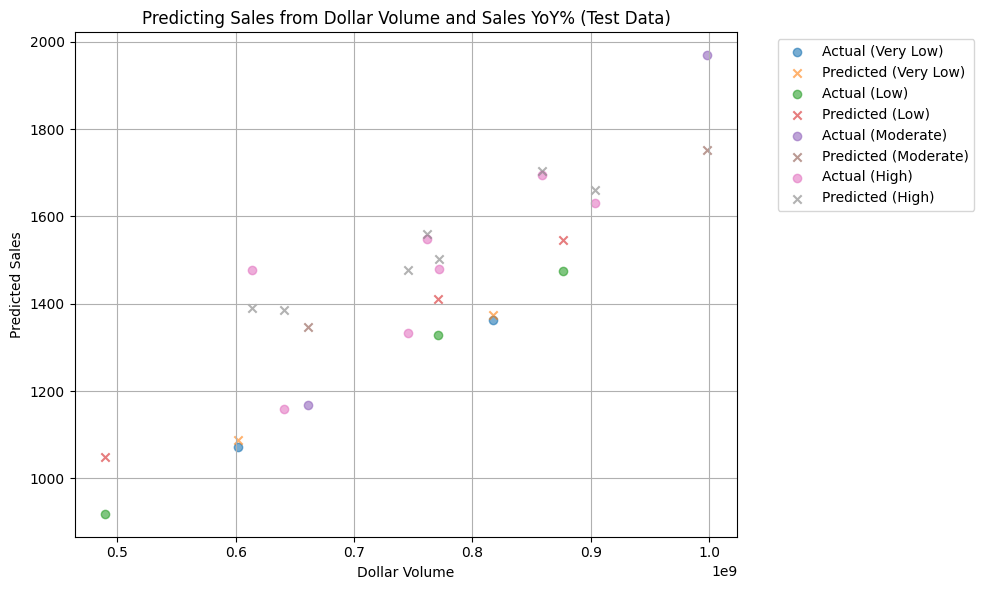

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Make sure Date is datetime
df['Date'] = pd.to_datetime(df['Date'])

# Filter to 2020–2025
df_filtered = df_filtered[(df_filtered['Date'].dt.year >= 2020) & (df_filtered['Date'].dt.year <= 2025)]

# --- 1. Define features (X) and target (y) ---
X = df_filtered[['Dollar Volume', 'Sales YoY%']] # (Predictors) Average Price has a stronger correlation and Sales YoY% can show temporal trends
y = df_filtered['Sales']

# --- 2. Split into training and testing sets ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=8
)

# --- 3. Train model ---
model = LinearRegression()
model.fit(X_train, y_train)

# --- 4. Predict on test set ---
y_pred = model.predict(X_test)

# --- 5. Evaluate performance ---
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Coefficients:")
for name, coef in zip(X_train.columns, model.coef_):
    print(f"  {name}: {coef:.2f}")
print(f"Intercept: {model.intercept_:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")

bins = [df_filtered['Sales YoY%'].min()-0.01, -0.1, 0, 0.1, df_filtered['Sales YoY%'].max()+0.01] # Because Dollar Volume is continuous, bin to make discrete intervals
labels = ['Very Low', 'Low', 'Moderate', 'High']
X_test['YoY Bin']=pd.cut(X_test['Sales YoY%'], bins=bins, labels=labels)

# --- 6. Visualize
plt.figure(figsize=(10,6))
for label in labels:
  mask = X_test['YoY Bin'] == label
  plt.scatter(
      X_test.loc[mask, 'Dollar Volume'], y_test[mask],
      alpha=0.6, label=f'Actual ({label})'
  )
  plt.scatter(
      X_test.loc[mask, 'Dollar Volume'], y_pred[mask],
      alpha=0.6, marker='x', label=f'Predicted ({label})'
  )

plt.title("Predicting Sales from Dollar Volume and Sales YoY% (Test Data)")
plt.xlabel("Dollar Volume")
plt.ylabel("Predicted Sales")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

For every 1% increase in Sales YoY%, the predicted sales increase by 4.88 homes. For every 100% increase, the predicted sales increase by 487.62. On the other hand, Dollar Volume's coefficient is 0, signifying that the changes in total revenue do not predict the number of homes sold. It is also because the scale for Dollar Volume is huge (millions), compressing the coefficient to 0. The R^2 value shows that 80% of the variation in sales is explained by these variables, but clearly the prediction comes from Sales YoY%.

So, while YoY% does not strongly correlate with Dollar Volume, it does correlate with whether sales are increasing or decreasing. I chose to exclude the use of Average or Median price variables in this model because they are highly correlated with Sales, which may cause multicollinearity and possible redundant information. Sales YoY% was included because it provides unique variance of market momentum to the prediction of sales.

The results indicate that demand trends, not total market revenue, determine the number of homes sold in a given month. It makes sense because Dollar Volume = Price x Sales (price can disort Dollar Volume). If fewer homes sell but prices double, Dollar Volume can still be high.

#Logistic Regression

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd

# Make sure Date is datetime
df['Date'] = pd.to_datetime(df['Date'])

# Filter to 2020–2025
df_filtered = df_filtered[(df_filtered['Date'].dt.year >= 2020) & (df_filtered['Date'].dt.year <= 2025)]

# Binary target
df_filtered['High_Sales'] = (df_filtered['Sales'] > df_filtered['Sales'].median()).astype(int)

# --- 1. Define features and target ---
features = ['Dollar Volume', 'Sales YoY%']
target = 'High_Sales'

# --- 2. One-hot encode categorical columns ---
X = pd.get_dummies(df_filtered[features], drop_first=True)
y = df_filtered[target]

# --- 3. Split into training and testing sets ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 70 entries, 0 to 69
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Dollar Volume  70 non-null     int64  
 1   Sales YoY%     70 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 1.6 KB


## Train and evaluate the logistic regression model


Model Evaluation Metrics:
Accuracy:  0.857
Precision: 0.857
Recall:    0.857
F1 Score:  0.857

Feature Impact on High Sales (Logistic Regression Coefficients):
         Feature  Coefficient  Odds_Ratio
0  Dollar Volume     1.964891    7.134134
1     Sales YoY%     1.003500    2.727813


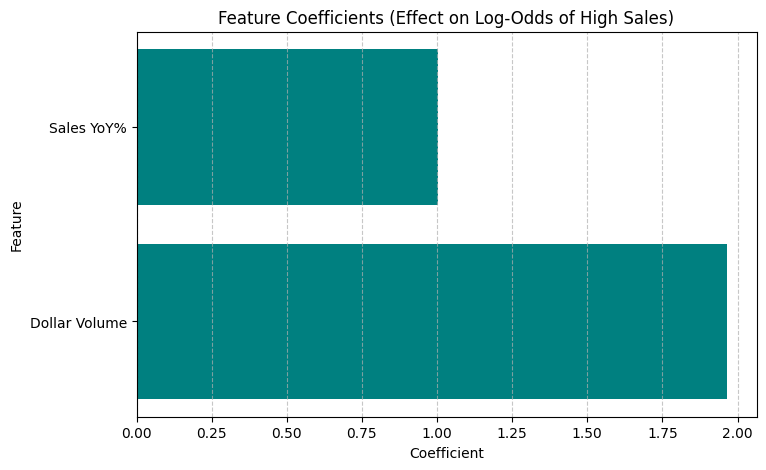

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Features and target ---
features = ['Dollar Volume', 'Sales YoY%']
target = 'High_Sales'

X = df_filtered[features]
y = df_filtered[target]

# --- Train/test split ---
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# --- Scale features ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- Train logistic regression ---
model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train_scaled, y_train)

# --- Predict ---
y_pred = model.predict(X_test_scaled)

# --- Evaluate ---
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Model Evaluation Metrics:")
print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1 Score:  {f1:.3f}")

# --- Feature importance ---
coef_df = pd.DataFrame({
    'Feature': features,   # use the original column names
    'Coefficient': model.coef_[0],
    'Odds_Ratio': np.exp(model.coef_[0])
}).sort_values(by='Odds_Ratio', ascending=False)

print("\nFeature Impact on High Sales (Logistic Regression Coefficients):")
print(coef_df)

# --- Visualization ---
plt.figure(figsize=(8,5))
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color='teal')
plt.title("Feature Coefficients (Effect on Log-Odds of High Sales)")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.grid(True, axis='x', linestyle='--', alpha=0.7)
plt.show()


The model accurately predicts high sales months well. It captured this pattern as accuracy, precision, recall, and the F1 score were at 85.7%. The accuracy percentage means the model correctly labeled 85.7% of all months as high-sales or not. The precision percentage answers when the model predicts a high-sales month, how often is it correct. 85.7% means there were few false posiitives. The recall percentage refers to of all actual high-sales months, how many did the model successfully detect, and the model rarely missed important high-activity periods. The F1 score means the model is balanced in detecting high sales months without producting too many false positives.

The factors that increase the odds that a month is a high sales month are Dollar Volume, with the strongest odds ratio of 7.13, and Sales YoY% with 2.73. So, for every 1 unit increase of Dollar Volume, the odds of it being a high sales month increase by 7.1x. For Sales YoY%, the odds increase by 2.7x.

The months with a higher Dollar Volume are very likely to be high sales months. In other words, high sales months are months that generate a high total revenue. As discussed in the linear regression model, this does not mean Dollar Volume can meaningfully predict the number of homes sold (sales). This indicates that the total market revenue and demand growth drive those high selling months.